# Домашнее задание 1 · Персональные top-10 рекомендации
**Петраков Степан Дмитриевич**

Пять моделей с нуля: ItemKNN, iALS, EASE, FM с метапризнаками и ALS с авторским целевым сигналом. Датасет: **Amazon Reviews 2018, Digital Music, 5-core**.

Задача: рекомендовать пользователю 10 ещё не оценённых музыкальных товаров Amazon. Единица взаимодействия — опубликованный отзыв, а не прослушивание или покупка. **Релевантность фиксирована для всех моделей: первая оценка товара пользователем ≥ 4**. Основная метрика, выбранная до подбора, — **NDCG@10**, дополнительные — Recall@10 и покрытие каталога.

## 1. Воспроизводимый запуск
Python 3.12; CPU, 2 потока, seed=42. Из корня репозитория:
```bash
python3.12 -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt
python -m pytest -q
python run_notebook.py
```
Первый запуск скачивает около 20 MB в `data/`; файл проверяется SHA-256. Данные и окружение не включены в GitHub. `run_notebook.py` выполняет все ячейки и сохраняет результаты в этот ноутбук. Альтернативный запуск вычислений без графиков: `python experiment.py`.


In [1]:
import json, platform, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from data_utils import load_data, matrices, train_metadata, DATA_URL, DATA_SHA256, TRAIN_END, VALID_END
from evaluation import evaluation_set
from experiment import SEARCH, SEED, PRIMARY_METRIC, select_parameters, final_comparison

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})
Path('results').mkdir(exist_ok=True)
print({'python': sys.version.split()[0], 'platform': platform.system(), 'machine': platform.machine(),
       'numpy': np.__version__, 'pandas': pd.__version__, 'torch': torch.__version__,
       'seed': SEED, 'primary_metric': PRIMARY_METRIC, 'torch_threads': torch.get_num_threads()})

{'python': '3.12.14', 'platform': 'Darwin', 'machine': 'arm64', 'numpy': '2.5.4', 'pandas': '3.1.0', 'torch': '2.14.1', 'seed': 42, 'primary_metric': 'ndcg@10', 'torch_threads': 2}


## 2. Источник и поля
[Первоисточник: Jianmo Ni / UCSD](https://nijianmo.github.io/amazon/index.html), раздел Digital Music → 5-core. [Действующий официальный файл](https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Digital_Music_5.json.gz).

Цитирование датасета: Ni, Li, McAuley. *Justifying Recommendations using Distantly-Labeled Reviews and Fine-Grained Aspects*, EMNLP 2019, [статья](https://aclanthology.org/D19-1018/).

| Поле источника | Значение | Использование |
|---|---|---|
| reviewerID | Идентификатор автора отзыва | Код пользователя |
| asin | Идентификатор музыкального товара | Код объекта |
| overall | Оценка от 1 до 5 | Релевантность и обучающий таргет |
| unixReviewTime | Время отзыва, Unix seconds | Разбиение, давность истории, кастомный таргет |

Имена пользователей, тексты отзывов и голоса полезности не используются. Дата будущего отзыва и его оценка **не передаются в FM при предсказании**. Другие товарные метаданные из позднего снимка каталога не нужны; метапризнаки строятся по наблюдаемой к моменту рекомендации истории и её timestamps.


In [2]:
selected, train, valid, test, shape, audit = load_data()
Path('results/data_audit.json').write_text(json.dumps(audit, ensure_ascii=False, indent=2))
display(pd.DataFrame([{'показатель': k, 'значение': v} for k,v in audit.items() if not isinstance(v, dict)]))
print('Пропуски:', audit['missing'])
print('SHA-256:', DATA_SHA256)
print('Размер модели (пользователи train, объекты):', shape)

,показатель,значение
0,raw_rows,169781
1,repeated_user_item_rows,24489
2,exact_tuple_duplicates,23863
3,clean_rows,145292
4,selected_rows,107777
5,selected_users,16427
6,selected_items,6000
7,train_rows,82964
8,validation_rows,12302
9,test_rows,12511


Пропуски: {'uid': 0, 'iid': 0, 'rating': 0, 'timestamp': 0}
SHA-256: 703f60f74bf1967a75cbb3033532172eeb21139d4df04ec5fe44a7eb8d7fde58
Размер модели (пользователи train, объекты): (14084, 6000)


## 3. Очистка, подвыборка и EDA
Удаляются строки с пропущенными ключами, оценками вне [1,5] и некорректным временем. Для повторной пары user–item сохраняется **первое** событие; при одинаковом timestamp — первая строка в исходном файле. Это фиксирует первую возможность рекомендовать объект и не переносит позднюю оценку в прошлое.

Каталог ограничен 6 000 товарами с наибольшим числом отзывов **только до TRAIN_END**. При равенстве частоты используется лексикографический ASIN. Все их очищенные взаимодействия сохраняются, в том числе для аудита новых пользователей. Выбор снижает квадратичную память EASE и смещает оценку к популярным товарам; выводы не распространяются на длинный хвост полного каталога. Выбор по будущей популярности не используется.

Границы времени соответствуют примерно 70% и 85% очищенного полного массива по timestamp, зафиксированы в коде до обучения. Подбор не меняет границы или каталог. Уже исходный 5-core построен авторами по всему периоду: это ретроспективное условие отбора, поэтому эксперимент не имитирует полностью несмещённый промышленный поток.


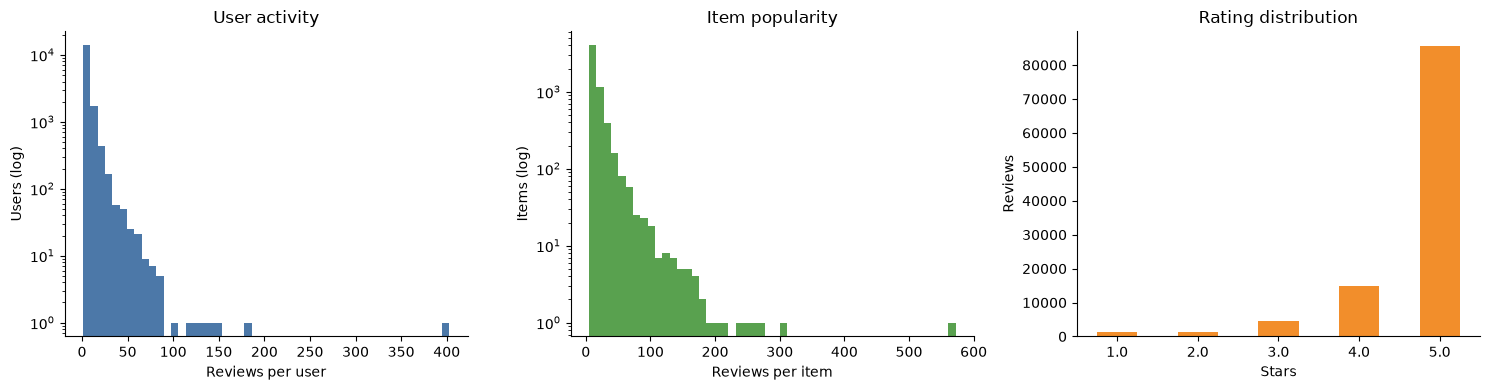

Разреженность: 99.8907%; доля оценок ≥4: 93.34%


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
selected.groupby('uid').size().plot.hist(bins=50, logy=True, ax=axes[0], color='#4C78A8')
axes[0].set(title='User activity', xlabel='Reviews per user', ylabel='Users (log)')
selected.groupby('iid').size().plot.hist(bins=50, logy=True, ax=axes[1], color='#59A14F')
axes[1].set(title='Item popularity', xlabel='Reviews per item', ylabel='Items (log)')
selected.rating.value_counts().sort_index().plot.bar(ax=axes[2], color='#F28E2B', rot=0)
axes[2].set(title='Rating distribution', xlabel='Stars', ylabel='Reviews')
plt.tight_layout(); plt.show()
print(f"Разреженность: {audit['sparsity']:.4%}; доля оценок ≥4: {(selected.rating>=4).mean():.2%}")

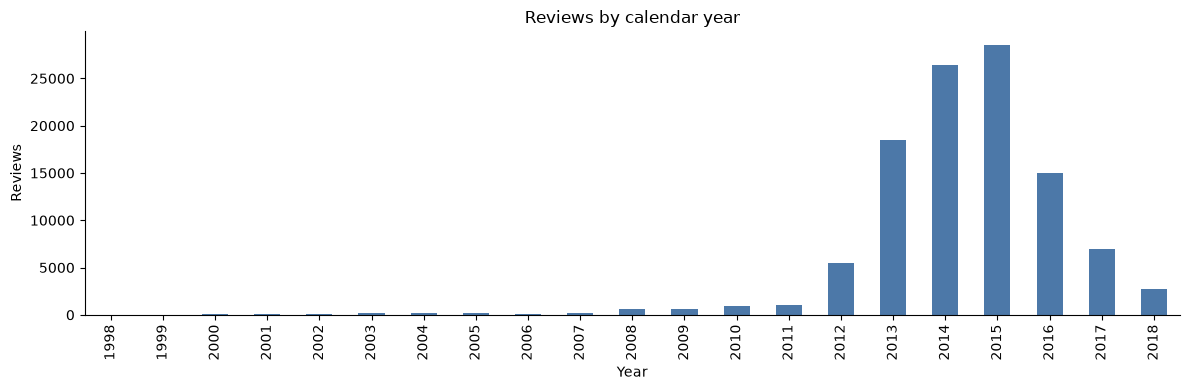

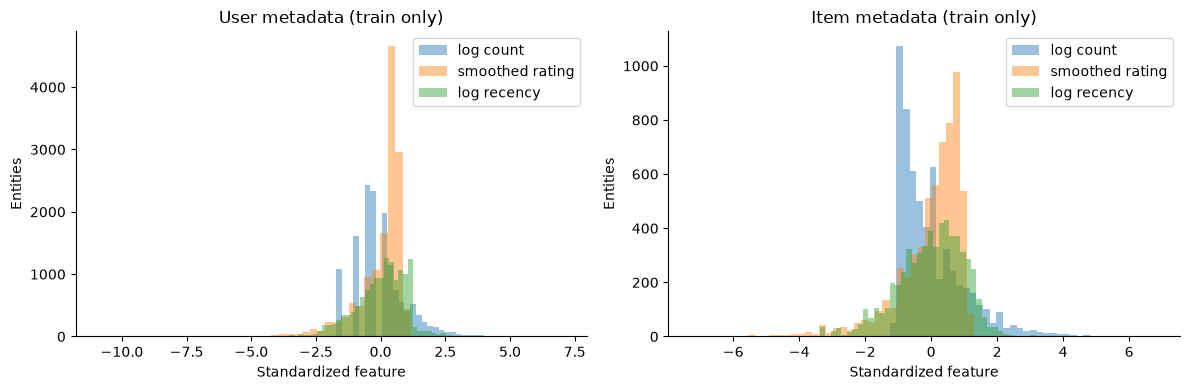

,feature,missing
0,user_log_count,0
1,user_mean_rating,0
2,user_log_recency,0
3,item_log_count,0
4,item_mean_rating,0
5,item_log_recency,0


In [4]:
timeline = pd.to_datetime(selected.timestamp, unit='s', utc=True).dt.year.value_counts().sort_index()
ax = timeline.plot.bar(color='#4C78A8', figsize=(12,4))
ax.set(title='Reviews by calendar year', xlabel='Year', ylabel='Reviews')
plt.tight_layout(); plt.show()
um, im = train_metadata(train, shape, TRAIN_END)
fig, axes = plt.subplots(1, 2, figsize=(12,4))
for idx, label in enumerate(['log count', 'smoothed rating', 'log recency']):
    axes[0].hist(um[:,idx], bins=40, alpha=.45, label=label)
    axes[1].hist(im[:,idx], bins=40, alpha=.45, label=label)
for ax, title in zip(axes, ['User metadata (train only)', 'Item metadata (train only)']):
    ax.set(title=title, xlabel='Standardized feature', ylabel='Entities'); ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame({'feature':['user_log_count','user_mean_rating','user_log_recency',
                                'item_log_count','item_mean_rating','item_log_recency'],
                      'missing':[int(np.isnan(x).sum()) for x in [um[:,0],um[:,1],um[:,2],im[:,0],im[:,1],im[:,2]]]}))

## 4. Единый протокол оценки

| Этап | Временной интервал UTC | История, доступная моделям |
|---|---|---|
| Train | t < 2015-12-29 | Только train |
| Validation | 2015-12-29 ≤ t < 2016-09-28 | Только train |
| Test | t ≥ 2016-09-28 | Train + validation после фиксации настроек |

В каждой фазе рекомендация строится на начало окна; внутри окна история не обновляется. Test покрывает длинный остаточный период, поэтому это задача поиска будущих релевантных товаров, а не next-item или online replay.

**Кандидаты:** полный фиксированный каталог 6 000 товаров минус все уже оценённые товары пользователя, включая оценки <4. Негативные кандидаты при оценке не сэмплируются. При равенстве score побеждает меньший код объекта (ASIN отсортирован).

**Cold start:** пользователи без train-истории исключаются из оценки всех моделей одинаково и учитываются в аудите. Каталог не расширяется новыми товарами; покупки вне него не входят в знаменатель Recall. Пользователи без хотя бы одного доступного релевантного объекта в соответствующем holdout исключаются: иначе Recall/NDCG не определены. Это условная оценка warm-start, а не охват всех пользователей; validation- и test-когорты могут различаться между собой, но внутри каждой фазы одинаковы для всех моделей.

$$Recall@10(u)=\frac{|R_u^{10}\cap G_u|}{|G_u|}.$$
$$NDCG@10(u)=\frac{\sum_{j=1}^{10}\mathbf{1}[R_{uj}\in G_u]/\log_2(j+1)}{\sum_{j=1}^{\min(10,|G_u|)}1/\log_2(j+1)}.$$

Метрики усредняются **по пользователям**, без взвешивания числом отзывов. NDCG учитывает позицию релевантного товара; Recall — долю будущих интересов, найденных в коротком списке. Coverage — доля каталога, показанная хотя бы одному оцениваемому пользователю, без утверждения о качестве. Для двух заранее заданных сравнений применяется парный bootstrap пользователей (2 000 повторов, seed=42); интервалы описательные, без поправки на множественные сравнения и без учёта случайности обучения.


In [5]:
seen_train = matrices(train, shape)[0]
valid_truth, valid_info = evaluation_set(valid, seen_train)
# До выбора настроек показываем только аудит train/validation, не test-метрики.
display(pd.DataFrame([valid_info], index=['validation']))
print('Наблюдения train:', len(train))
print('Дата максимального train-события:', pd.to_datetime(train.timestamp.max(), unit='s', utc=True))
print('Дата минимального validation-события:', pd.to_datetime(valid.timestamp.min(), unit='s', utc=True))
assert train.timestamp.max() < valid.timestamp.min()
assert len(selected) >= 100000 and selected.uid.nunique() >= 1000 and shape[1] >= 1000

,holdout_rows,cold_user_rows,known_users_without_relevant,evaluated_users,relevant_pairs
validation,12302,6280,90,2369,5748


Наблюдения train: 82964
Дата максимального train-события: 2015-12-28 00:00:00+00:00
Дата минимального validation-события: 2015-12-29 00:00:00+00:00


## 5. Модели и математические основания
Обучение, предсказания, ранжирование и метрики реализованы в репозитории. NumPy/SciPy используются для линейной алгебры, PyTorch — для autograd и Adam, готовых рекомендательных алгоритмов нет.

### 5.1 ItemKNN — `models/item_knn.py`
Пусть $X_{ui}=1[r_{ui}\ge4]$. Сходство товаров — cosine с усадкой по числу общих пользователей:
$$s_{ij}=\frac{X_i^TX_j}{\|X_i\|\|X_j\|}\frac{n_{ij}}{n_{ij}+\gamma},\quad s_{ii}=0.$$
Для каждого целевого товара оставляем K соседей. Предсказание $\hat r_{ui}=\sum_j X_{uj}s_{ji}$. Для нулевых норм сходство равно 0. Формула соответствует item-based neighborhood CF; выбор усадки и соседей проверяется на validation. [Sarwar et al., 2001](https://doi.org/10.1145/371920.372071).

### 5.2 iALS — `models/ials.py`
Наблюдаемые оценки переводим в бинарное предпочтение $p_{ui}=1[r_{ui}\ge4]$; для пропущенных пар $p=0$. Все наблюдаемые пары, включая низкие оценки, имеют $c_{ui}=1+\alpha$, ненаблюдаемые — $c=1$.
$$L=\sum_{u,i}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2).$$
$$x_u=(Y^TY+\alpha\sum_{i\in O_u}y_iy_i^T+\lambda I)^{-1}\sum_{i\in O_u}(1+\alpha)p_{ui}y_i.$$
Обновление объектов симметрично; используется `solve`, не явное обращение каждой малой матрицы. Формула Hu–Koren–Volinsky адаптирована к событиям положительной/неположительной оценки: это авторская бинаризация явного сигнала, а не утверждение, что любой отзыв означает интерес. [Hu et al., 2008](https://yifanhu.net/PUB/cf.pdf).

### 5.3 EASE — `models/ease.py`
$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\quad diag(B)=0.$$
$$P=(X^TX+\lambda I)^{-1},\quad B_{ij}=-P_{ij}/P_{jj}\ (i\ne j),\quad B_{jj}=0.$$
Решение получено через Cholesky, prediction — $XB$. Диагональное ограничение предотвращает тождественное копирование входа. [Steck, 2019](https://arxiv.org/abs/1905.03375).

### 5.4 FM с метапризнаками — `models/fm.py`
$$\hat y(z)=w_0+\sum_jw_jz_j+\tfrac12\sum_f[(\sum_jv_{jf}z_j)^2-\sum_jv_{jf}^2z_j^2].$$
Признаки: user ID, item ID и **6 числовых метапризнаков** — для пользователя и товара отдельно: log1p(число отзывов), сглаженная средняя оценка, log1p(дни с последнего отзыва). Сглаживание: $(\sum r+5\bar r_{train})/(n+5)$. Стандартизация рассчитывается по обучающим сущностям. Это активность, склонность к высоким оценкам/качество объекта и давность интереса. Все признаки являются снимком истории **до текущей границы обучения**, затем фиксируются на holdout. При финальном refit пересчитываются по train+validation до начала test.

BCE-with-logits: оценки ≥4 — положительные, остальные наблюдаемые — отрицательные; на каждое положительное событие в каждой эпохе добавляются 2 равномерных ненаблюдавшихся объекта того же пользователя. Будущие отзывы не используются при отрицательном сэмплировании; возможные будущие положительные могут попасть в negatives — обычное ограничение такого обучения. Сэмплирование применяется только к обучению, оценка идёт по всему каталогу. Регуляризация — L2 через `Adam(weight_decay=...)`.

Предсказание FM ускорено точным разложением на внутренние взаимодействия признаков пользователя, объекта и их скалярное произведение. Эквивалентность исходной попарной формуле проверяется отдельным тестом. [Rendle, 2010](https://doi.org/10.1109/ICDM.2010.127).

### 5.5 ALS с кастомным таргетом — `models/custom_als.py`
Авторская гипотеза: сильно положительные/отрицательные оценки нужно отличать от умеренных, а старые предпочтения частично ослаблять. Для наблюдаемой пары:
$$p^*_{ui}=\mathrm{clip}\left(\frac{r_{ui}-3}{2},-1,1\right)\left(0.5+0.5\cdot2^{-(T-t_{ui})/(86400\cdot365)}\right).$$
Для ненаблюдаемых пар $p^*=0$. Здесь T — начало holdout, 365 дней — заранее выбранный период полураспада; коэффициент 0.5 сохраняет долгосрочную часть музыкального вкуса. Это **проектное допущение**, не оценённый по данным срок забывания. Рейтинги 1–2 дают отрицательную цель, 3 — 0, 4–5 — положительную разной силы.

**Confidence c, функция потерь и алгоритм ALS остаются теми же, меняется именно p.** Например, оценка 4 годичной давности даёт 0.375 вместо 1, оценка 1 — −0.75 вместо 0. Для причинной интерпретации это не годится: проверяется качество ранжирования при новой эвристической цели. Нужен эксперимент, а не предположение об обязательном улучшении. Помимо собственного подбора, предусмотрено сравнение кастомного сигнала с базовым iALS при **одинаковых выбранных для iALS настройках**.


## 6. Подбор на validation
Основная метрика — NDCG@10, tie-break — первая конфигурация в объявленном порядке. Пространство маленькое и фиксированное: это честный ограниченный поиск, не доказательство глобального оптимума. У каждой модели несколько конфигураций; FM обучается 10 эпох, ALS — 10 полных чередований. Test не используется для выбора эпох, признаков, формулы таргета и гиперпараметров.


In [6]:
display(pd.DataFrame([{'model': name, 'configurations': len(choices), 'search_space': json.dumps(choices, ensure_ascii=False)} for name, choices in SEARCH.items()]))
selection = select_parameters(train, valid, shape)
validation_table = pd.DataFrame(selection['validation'])
display(validation_table[['model','params','ndcg@10','recall@10','coverage@10','fit_seconds']])
display(pd.DataFrame([{'model': k, 'selected_parameters': v} for k,v in selection['best'].items()]))

,model,configurations,search_space
0,ItemKNN,4,"[{""neighbors"": 30, ""shrinkage"": 0.0}, {""neighb..."
1,iALS,4,"[{""factors"": 16, ""regularization"": 1.0, ""alpha..."
2,EASE,3,"[{""regularization"": 10.0}, {""regularization"": ..."
3,FM,4,"[{""factors"": 16, ""regularization"": 1e-05, ""epo..."
4,CustomALS,4,"[{""factors"": 16, ""regularization"": 1.0, ""alpha..."


ItemKNN {'neighbors': 30, 'shrinkage': 0.0} {'ndcg@10': 0.018574554694809675, 'recall@10': 0.028085997057489303, 'coverage@10': 0.8618333333333333, 'users': 2369}


ItemKNN {'neighbors': 30, 'shrinkage': 20.0} {'ndcg@10': 0.02126401999705646, 'recall@10': 0.033285029750620115, 'coverage@10': 0.8063333333333333, 'users': 2369}


ItemKNN {'neighbors': 100, 'shrinkage': 0.0} {'ndcg@10': 0.018441417724576376, 'recall@10': 0.027461975190326872, 'coverage@10': 0.8551666666666666, 'users': 2369}


ItemKNN {'neighbors': 100, 'shrinkage': 20.0} {'ndcg@10': 0.021538522895907623, 'recall@10': 0.034428760790931996, 'coverage@10': 0.7741666666666667, 'users': 2369}


...

CustomALS {'factors': 16, 'regularization': 10.0, 'alpha': 20.0, 'iterations': 10, 'half_life_days': 365.0, 'seed': 42} {'ndcg@10': 0.024727952131153468, 'recall@10': 0.03968229002423707, 'coverage@10': 0.08733333333333333, 'users': 2369}


CustomALS {'factors': 32, 'regularization': 1.0, 'alpha': 20.0, 'iterations': 10, 'half_life_days': 365.0, 'seed': 42} {'ndcg@10': 0.027778498455776925, 'recall@10': 0.04591776732893295, 'coverage@10': 0.17366666666666666, 'users': 2369}


CustomALS {'factors': 32, 'regularization': 10.0, 'alpha': 20.0, 'iterations': 10, 'half_life_days': 365.0, 'seed': 42} {'ndcg@10': 0.02794579680655466, 'recall@10': 0.04588713097630321, 'coverage@10': 0.1635, 'users': 2369}


,model,params,ndcg@10,recall@10,coverage@10,fit_seconds
0,ItemKNN,"{'neighbors': 30, 'shrinkage': 0.0}",0.018575,0.028086,0.861833,0.749223
1,ItemKNN,"{'neighbors': 30, 'shrinkage': 20.0}",0.021264,0.033285,0.806333,0.634890
2,ItemKNN,"{'neighbors': 100, 'shrinkage': 0.0}",0.018441,0.027462,0.855167,0.628064
3,ItemKNN,"{'neighbors': 100, 'shrinkage': 20.0}",0.021539,0.034429,0.774167,0.649832
4,iALS,"{'factors': 16, 'regularization': 1.0, 'alpha'...",0.018616,0.034534,0.090833,1.613805
5,iALS,"{'factors': 16, 'regularization': 10.0, 'alpha...",0.018855,0.035342,0.087667,1.608006
6,iALS,"{'factors': 32, 'regularization': 1.0, 'alpha'...",0.023171,0.040301,0.168833,2.682339
7,iALS,"{'factors': 32, 'regularization': 10.0, 'alpha...",0.022915,0.039454,0.163167,2.714123
8,EASE,{'regularization': 10.0},0.022090,0.033649,0.781333,1.015640
9,EASE,{'regularization': 100.0},0.023515,0.038421,0.710833,1.130372


,model,selected_parameters
0,ItemKNN,"{'neighbors': 100, 'shrinkage': 20.0}"
1,iALS,"{'factors': 32, 'regularization': 1.0, 'alpha'..."
2,EASE,{'regularization': 100.0}
3,FM,"{'factors': 16, 'regularization': 1e-05, 'epoc..."
4,CustomALS,"{'factors': 32, 'regularization': 10.0, 'alpha..."


## 7. Финальная оценка на test
Настройки уже записаны в `results/selection.json`. Пять моделей переобучаются на train+validation. Дополнительно выполняются **два заранее объявленных контроля**: FM без метапризнаков с теми же настройками и custom ALS с настройками базового iALS. Контроли не заменяют обязательную модель FM с метапризнаками и не участвуют в последующем подборе.


In [7]:
final = final_comparison(train, valid, test, shape, selection)
results = pd.DataFrame(final['test'])
main_results = results[results.model.isin(SEARCH)].sort_values('ndcg@10', ascending=False)
display(main_results[['model','params','ndcg@10','recall@10','coverage@10','fit_seconds','evaluation_seconds']])
display(pd.DataFrame([final['test_cohort']], index=['test']))
display(results[~results.model.isin(SEARCH)][['model','params','ndcg@10','recall@10','coverage@10']])

TEST ItemKNN {'ndcg@10': 0.022869781900395365, 'recall@10': 0.036753852824641386, 'coverage@10': 0.7115, 'users': 1897}


TEST iALS {'ndcg@10': 0.02178053422464087, 'recall@10': 0.03346764814872353, 'coverage@10': 0.16283333333333333, 'users': 1897}


TEST EASE {'ndcg@10': 0.027775675412539755, 'recall@10': 0.043598312161999254, 'coverage@10': 0.6235, 'users': 1897}


TEST FM {'ndcg@10': 0.007849851674704473, 'recall@10': 0.01429760395316012, 'coverage@10': 0.099, 'users': 1897}


TEST CustomALS {'ndcg@10': 0.02248296111929825, 'recall@10': 0.03531768593437211, 'coverage@10': 0.159, 'users': 1897}


TEST FM_ID_only {'ndcg@10': 0.018818663475344867, 'recall@10': 0.034342881002245466, 'coverage@10': 0.057833333333333334, 'users': 1897}


TEST CustomALS_matched {'ndcg@10': 0.022113943396778423, 'recall@10': 0.03580563857936839, 'coverage@10': 0.168, 'users': 1897}


,model,params,ndcg@10,recall@10,coverage@10,fit_seconds,evaluation_seconds
2,EASE,{'regularization': 100.0},0.027776,0.043598,0.623500,1.005388,3.986848
0,ItemKNN,"{'neighbors': 100, 'shrinkage': 20.0}",0.022870,0.036754,0.711500,0.767813,0.131254
4,CustomALS,"{'factors': 32, 'regularization': 10.0, 'alpha...",0.022483,0.035318,0.159000,2.856631,0.526379
1,iALS,"{'factors': 32, 'regularization': 1.0, 'alpha'...",0.021781,0.033468,0.162833,2.867255,0.520798
3,FM,"{'factors': 16, 'regularization': 1e-05, 'epoc...",0.007850,0.014298,0.099000,1.639865,0.534128


,holdout_rows,cold_user_rows,known_users_without_relevant,evaluated_users,relevant_pairs
test,12511,7308,60,1897,4962


,model,params,ndcg@10,recall@10,coverage@10
5,FM_ID_only,"{'factors': 16, 'regularization': 1e-05, 'epoc...",0.018819,0.034343,0.057833
6,CustomALS_matched,"{'factors': 32, 'regularization': 1.0, 'alpha'...",0.022114,0.035806,0.168000


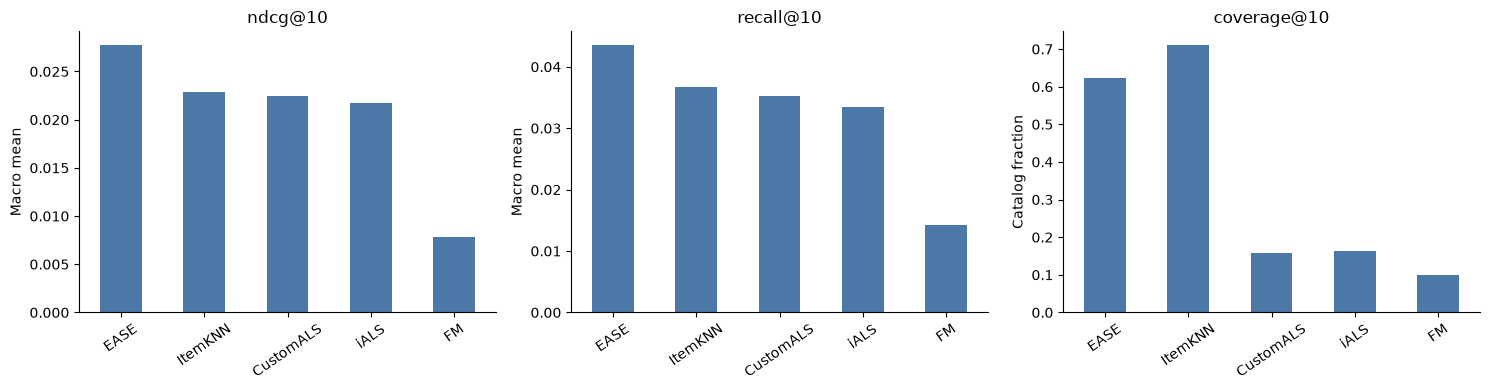

,delta,ci95_low,ci95_high
FM minus ID-only (matched settings),-0.010969,-0.014738,-0.007005
Custom minus iALS (matched settings),0.000333,-0.002557,0.003283


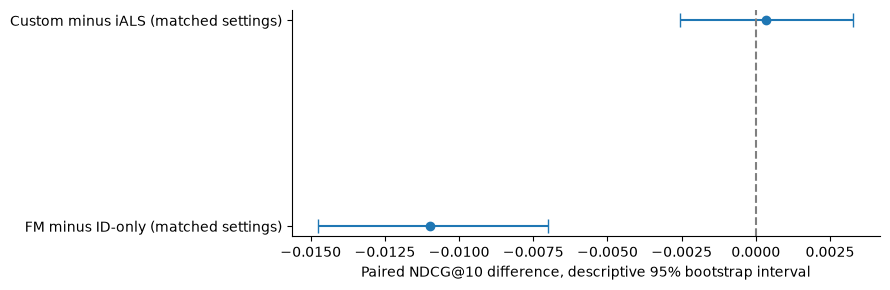

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, metric in zip(axes, ['ndcg@10','recall@10','coverage@10']):
    main_results.set_index('model')[metric].plot.bar(ax=ax, color='#4C78A8', rot=35)
    ax.set(title=metric, xlabel='', ylabel='Macro mean' if metric!='coverage@10' else 'Catalog fraction')
plt.tight_layout(); plt.show()
comparison = pd.DataFrame(final['paired_ndcg_differences']).T
display(comparison)
fig, ax = plt.subplots(figsize=(9,3))
y = np.arange(len(comparison))
ax.errorbar(comparison.delta, y, xerr=np.vstack([comparison.delta-comparison.ci95_low, comparison.ci95_high-comparison.delta]), fmt='o', capsize=5)
ax.axvline(0,color='gray',linestyle='--'); ax.set_yticks(y,comparison.index)
ax.set(xlabel='Paired NDCG@10 difference, descriptive 95% bootstrap interval')
plt.tight_layout(); plt.show()

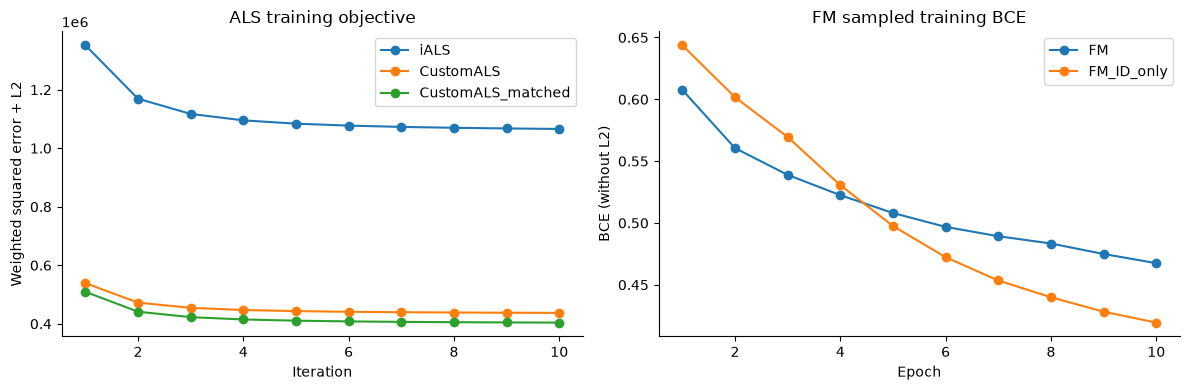

In [9]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
for name, curve in final['training_curves'].items():
    ax = axes[1] if name.startswith('FM') else axes[0]
    ax.plot(np.arange(1,len(curve)+1),curve,marker='o',label=name)
axes[0].set(title='ALS training objective',xlabel='Iteration',ylabel='Weighted squared error + L2')
axes[1].set(title='FM sampled training BCE',xlabel='Epoch',ylabel='BCE (without L2)')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

## 8. Выводы по выполненному эксперименту

In [10]:
winner = main_results.iloc[0]
fm_delta = final['paired_ndcg_differences']['FM minus ID-only (matched settings)']
custom_delta = final['paired_ndcg_differences']['Custom minus iALS (matched settings)']
def effect(d):
    direction = 'повышает' if d['delta']>0 else 'снижает'
    interval = f"[{d['ci95_low']:+.5f}; {d['ci95_high']:+.5f}]"
    certainty = 'интервал пересекает ноль' if d['ci95_low']<=0<=d['ci95_high'] else 'интервал не пересекает ноль'
    return f"{direction} NDCG@10 на {abs(d['delta']):.5f}; описательный 95% интервал {interval}, {certainty}"
report = f"""Лучший test NDCG@10 среди пяти основных моделей — **{winner['model']}**: **{winner['ndcg@10']:.5f}**, Recall@10 **{winner['recall@10']:.5f}**, покрытие каталога **{winner['coverage@10']:.2%}**. Настройки: `{winner['params']}`.

- Добавление исторических метапризнаков к FM при одинаковых настройках {effect(fm_delta)}. Это эффект именно данного набора агрегатов; он не характеризует любые товарные метаданные.
- Кастомный сигнал при одинаковых настройках базового iALS {effect(custom_delta)}. Эвристика оценивается по общей релевантности rating≥4, а не по своей обучающей цели.
- Оценка выполнена на **{final['test_cohort']['evaluated_users']}** пользователях, имеющих train-историю и хотя бы один доступный положительный test-объект. Пользовательский знаменатель одинаков для всех моделей.
- Из всех положительных test-событий очищенного датасета **{audit['test_outside_catalog_relevant']} / {audit['test_all_catalog_relevant']}** относятся к товарам вне выбранного каталога; они не входят в целевую популяцию этого эксперимента.
"""
display(Markdown(report))
Path('results/conclusions.md').write_text(report)

display(Markdown('Примеры top-10 для трёх одинаковых test-пользователей (локальные коды объектов; исходные идентификаторы не публикуются):'))
display(pd.DataFrame(final['top10_encoded_examples']).rename_axis('пример пользователя'))

Лучший test NDCG@10 среди пяти основных моделей — **EASE**: **0.02778**, Recall@10 **0.04360**, покрытие каталога **62.35%**. Настройки: `{'regularization': 100.0}`.

- Добавление исторических метапризнаков к FM при одинаковых настройках снижает NDCG@10 на 0.01097; описательный 95% интервал [-0.01474; -0.00701], интервал не пересекает ноль. Это эффект именно данного набора агрегатов; он не характеризует любые товарные метаданные.
- Кастомный сигнал при одинаковых настройках базового iALS повышает NDCG@10 на 0.00033; описательный 95% интервал [-0.00256; +0.00328], интервал пересекает ноль. Эвристика оценивается по общей релевантности rating≥4, а не по своей обучающей цели.
- Оценка выполнена на **1897** пользователях, имеющих train-историю и хотя бы один доступный положительный test-объект. Пользовательский знаменатель одинаков для всех моделей.
- Из всех положительных test-событий очищенного датасета **8883 / 20717** относятся к товарам вне выбранного каталога; они не входят в целевую популяцию этого эксперимента.


Примеры top-10 для трёх одинаковых test-пользователей (локальные коды объектов; исходные идентификаторы не публикуются):

,ItemKNN,iALS,EASE,FM,CustomALS,FM_ID_only,CustomALS_matched
пример пользователя,,,,,,,
0,"[5672, 5914, 4742, 5762, 5656, 2449, 4283, 477...","[5914, 723, 3455, 1170, 929, 4263, 4075, 4289,...","[5914, 5762, 4742, 5656, 5672, 5517, 1486, 578...","[4703, 4564, 4142, 5428, 4839, 1434, 4974, 135...","[5914, 723, 4263, 3455, 5517, 4, 1603, 3331, 5...","[4703, 1603, 5987, 3331, 5428, 5700, 4457, 525...","[5914, 723, 4263, 3455, 4, 5517, 5428, 5872, 5..."
1,"[5036, 5022, 4028, 3118, 4029, 5190, 1857, 418...","[4156, 4338, 4028, 3803, 4440, 5917, 5206, 311...","[4028, 5036, 4029, 5190, 5022, 1434, 3300, 311...","[4703, 4564, 4839, 4142, 5013, 3925, 4974, 143...","[3803, 4338, 4156, 4028, 4440, 5206, 4158, 519...","[4028, 4156, 1434, 3803, 79, 4338, 5372, 3881,...","[3803, 4338, 4156, 4028, 4440, 5206, 4158, 591..."
2,"[4156, 4835, 4185, 5455, 5306, 4569, 3994, 485...","[5511, 5936, 5306, 5987, 5372, 5456, 3797, 515...","[5306, 4156, 4185, 5455, 4835, 5125, 4986, 311...","[4703, 4830, 1434, 5766, 3803, 1157, 4142, 466...","[5511, 5306, 5987, 5936, 5156, 5233, 3797, 584...","[4703, 3797, 3149, 3495, 4163, 4839, 5033, 598...","[5511, 5306, 5987, 5936, 5156, 5233, 5561, 545..."


### Ограничения и границы проверки
1. Отзыв — смещённый сигнал: нет показов, реальных покупок и отрицательных откликов на рекомендации. Ненаблюдаемые объекты не обязательно нерелевантны. Нельзя интерпретировать Recall как конверсию.
2. 5-core и популярный ограниченный каталог исключают значительную часть хвоста; новые пользователи не оцениваются. Публикуются размеры исключений, а не утверждение о полном охвате.
3. Test — длинное статичное окно. Не моделируются изменения каталога и истории в течение периода; метрики нельзя прямо переносить на ежедневную выдачу.
4. Один seed и небольшой поиск не измеряют дисперсию обучения и не доказывают глобальный оптимум. Bootstrap учитывает только состав test-пользователей при фиксированных моделях.
5. Исторические агрегаты FM зависят от числа отзывов и оценок. Их абляция не доказывает причинный эффект метаданных и не заменяет проверку жанров/описаний.
6. Успешный запуск, проверка формул на синтетических примерах и применимость протокола — разные проверки. Unit-тесты подтверждают арифметику ALS, EASE, FM, маскирование, метрики и воспроизводимость; методические ограничения приведены выше.
7. Запрет MovieLens, Netflix Prize и Last.fm соблюдён. Список датасетов семинаров не предоставлен; отсутствие Digital Music в нём требует сверки с материалами курса.

### Артефакты
`results/data_audit.json`, `results/selection.json`, `results/final.json`, `results/test_metrics.csv`, `results/conclusions.md` содержат фактические агрегированные результаты. Исходные данные, модели и идентификаторы пользователей не публикуются.
